In [1]:
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

import os
import numpy as np
import matplotlib.pyplot as plt

import bilby
import pycbc
import pycbc.psd
import pycbc.noise
import pycbc.detector

**Loading the Einstein Telescope detectors using Bilby**

In [2]:
conda_prefix = os.environ['CONDA_PREFIX']
detector_filename = f"{conda_prefix}/lib/python3.11/site-packages/bilby/gw/detector/detectors/ET.interferometer"
ET1, ET2, ET3 = bilby.gw.detector.load_interferometer(filename=detector_filename)

In [3]:
dir(ET1)

['__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_filename_from_outdir_label_extension',
 '_load_docstring',
 '_save_ifo_docstring',
 '_window_power_correction',
 'amplitude_spectral_density_array',
 'antenna_response',
 'calibration_model',
 'check_signal_duration',
 'detector_tensor',
 'duration',
 'elevation',
 'frequency_array',
 'frequency_domain_strain',
 'frequency_mask',
 'from_pickle',
 'geometry',
 'get_detector_response',
 'get_whitened_time_series_from_whitened_frequency_series',
 'inject_signal',
 'inject_signal_from_waveform_generator',
 'inject_signal_from_waveform_polarizations',
 'inner_product',
 'latitude',
 'latitude_radians',
 'len

In [4]:
ET1.minimum_frequency, ET1.maximum_frequency

(10, 2048)

**Setting the strain data in ET1 detector**

In [5]:
ET1.set_strain_data_from_power_spectral_density(sampling_frequency=4096, duration=8)

In [6]:
len(ET1.power_spectral_density_array), len(ET1.frequency_array)

(16385, 16385)

(1, 1024)

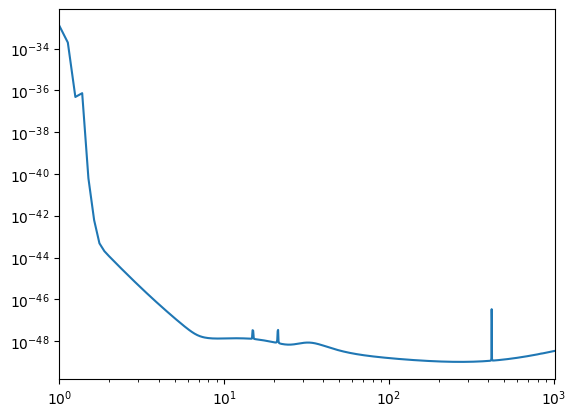

In [7]:
plt.plot(ET1.frequency_array, ET1.power_spectral_density_array)
plt.yscale('log')
plt.xscale('log')
plt.xlim(1, 1024)

In [8]:
np.array(pycbc.detector.ground.get_available_detectors())

array(['T1', 'V0', 'V1', 'G1', 'H2', 'H1', 'L1', 'I1', 'C1', 'E1', 'E2',
       'E3', 'E0', 'K1', 'U1', 'A1', 'O1', 'X1', 'N1', 'B1'], dtype='<U2')

In [9]:
E0 = pycbc.detector.ground.Detector(detector_name='E0')
E1 = pycbc.detector.ground.Detector(detector_name='E1')
E2 = pycbc.detector.ground.Detector(detector_name='E2')
E3 = pycbc.detector.ground.Detector(detector_name='E3')

In [10]:
dir(E1)

['__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 'antenna_pattern',
 'effective_distance',
 'get_icrs_pos',
 'gmst_estimate',
 'gmst_reference',
 'info',
 'lal',
 'latitude',
 'light_travel_time_to_detector',
 'location',
 'longitude',
 'name',
 'optimal_orientation',
 'project_wave',
 'reference_time',
 'response',
 'sday',
 'set_gmst_reference',
 'time_delay_from_detector',
 'time_delay_from_earth_center',
 'time_delay_from_location']

In [11]:
E1.info, E2.info, E3.info

({'location': array([4546374.09892846,  842989.69761976, 4378576.96265424]),
  'response': array([[ 0.16658988, -0.21884946, -0.1299639 ],
         [-0.21884946, -0.24838209,  0.27321496],
         [-0.1299639 ,  0.27321496,  0.08179221]]),
  'xresp': array([[-0.24532086,  0.07301909,  0.23905296],
         [ 0.07301909, -0.02173393, -0.07115347],
         [ 0.23905296, -0.07115347, -0.23294521]]),
  'yresp': array([[-0.07873098, -0.14583037,  0.10908906],
         [-0.14583037, -0.27011603,  0.20206149],
         [ 0.10908906,  0.20206149, -0.151153  ]]),
  'xvec': array([-0.70045821,  0.20848949,  0.68256166]),
  'yvec': array([-0.39681476, -0.7350048 ,  0.5498236 ]),
  'yangle': 5.575150489807129,
  'xangle': 0.3391628563404083,
  'height': 51.88399887084961,
  'xaltitude': 0.0,
  'yaltitude': 0.0,
  'ylength': 10000.0,
  'xlength': 10000.0},
 {'location': array([4539369.51678568,  845074.59246551, 4385402.57892966]),
  'response': array([[-0.19922116, -0.07022383,  0.21890042],
   

In [12]:
txt = np.loadtxt('ET_D.txt')
freqs, psd_strain = txt[:, 0], txt[:, 3]

data = np.column_stack((freqs, psd_strain))
np.savetxt('ETD_sum.txt', data, header='Frequency(Hz) PSD(Strain)', fmt='%.6e')

FileNotFoundError: ET_D.txt not found.

### Loading same PSD from various sources, i.e.
1. `psd0` corresponds to the ET PSD as given in bilby package.
2. `psd1` corresponds to the ET PSD as downloaded formm [ET website](https://apps.et-gw.eu/tds/?r=14065).
3. `psd2` corresponds to the ET PSD as given in `PyCBC` package.

In [13]:
bilby_psd_filename = f"{conda_prefix}/lib/python3.11/site-packages/bilby/gw/detector/noise_curves/ET_D_psd.txt"

In [23]:
psd0 = pycbc.psd.from_txt(filename=bilby_psd_filename, length=16385, delta_f=1/8, low_freq_cutoff=1, is_asd_file=False)

psd1 = pycbc.psd.from_txt(filename='ETD_sum.txt', length=16385, delta_f=1/8, low_freq_cutoff=1)

delta_f = 1 / 8
flen = int(4096 / (2 * delta_f)) + 1
psd2 = pycbc.psd.EinsteinTelescopeP1600143(flen, delta_f, 1)

psd3 = pycbc.psd.aLIGOZeroDetHighPower(flen, delta_f, 1)

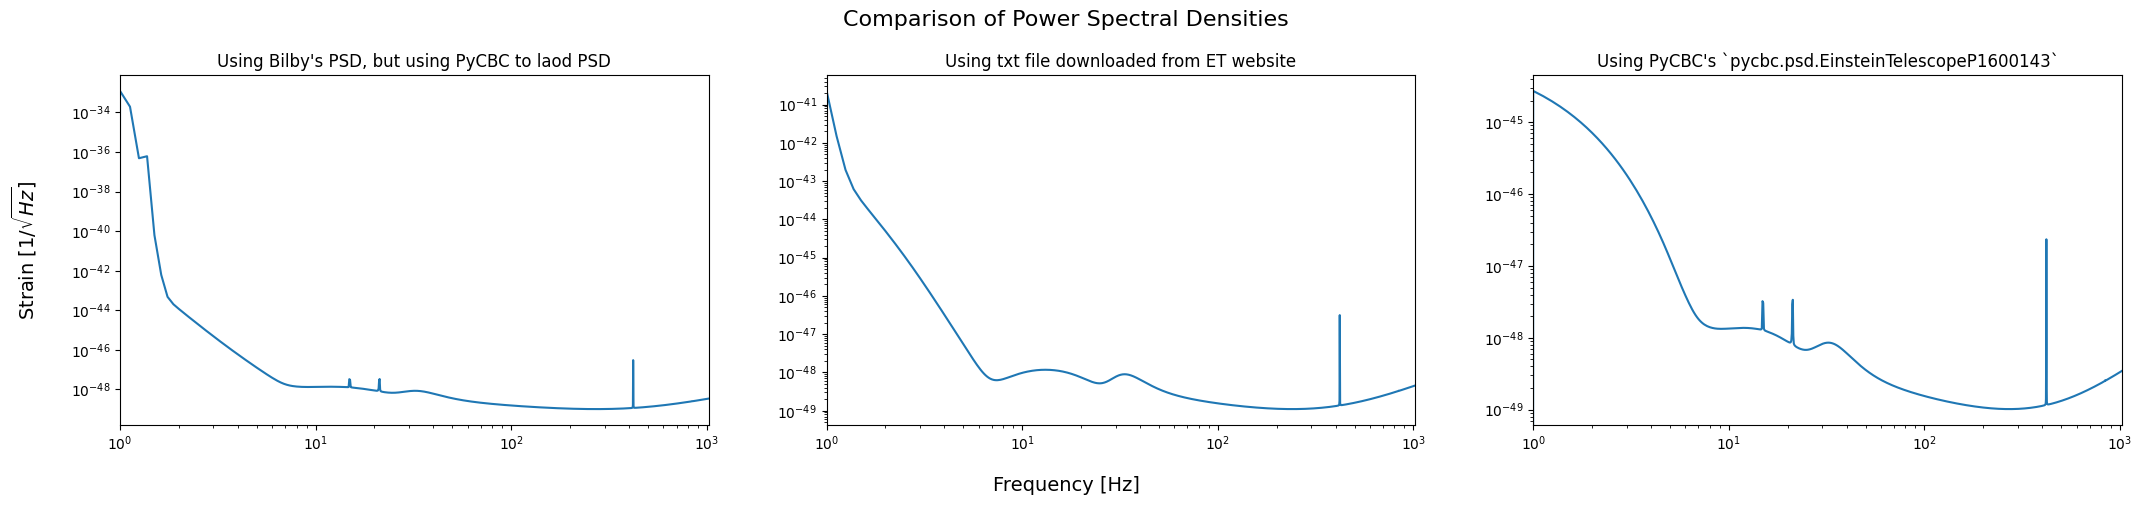

In [24]:
fig, axs = plt.subplots(1, 3, figsize=(22,5))

axs[0].plot(psd0.sample_frequencies, psd0.data) ### Why square root makes it equal to the one generated using same PSD file (I hope so), using Bilby?
axs[0].set_xscale('log')
axs[0].set_yscale('log')
axs[0].set_xlim(1, 1024)
axs[0].set_title("Using Bilby's PSD, but using PyCBC to laod PSD")

axs[1].plot(psd1.sample_frequencies, psd1.data)
axs[1].set_xscale('log')
axs[1].set_yscale('log')
axs[1].set_xlim(1, 1024)
axs[1].set_title("Using txt file downloaded from ET website")

axs[2].plot(psd2.sample_frequencies, psd2.data)
axs[2].set_xscale('log')
axs[2].set_yscale('log')
axs[2].set_xlim(1, 1024)
axs[2].set_title("Using PyCBC's `pycbc.psd.EinsteinTelescopeP1600143`")

fig.supxlabel("Frequency [Hz]", fontsize=14)
fig.supylabel(r"Strain [$1/\sqrt{Hz}$]", fontsize=14)
fig.suptitle("Comparison of Power Spectral Densities", fontsize=16)

fig.subplots_adjust(left=0.07, right=0.98, top=0.85, bottom=0.15)

plt.show()

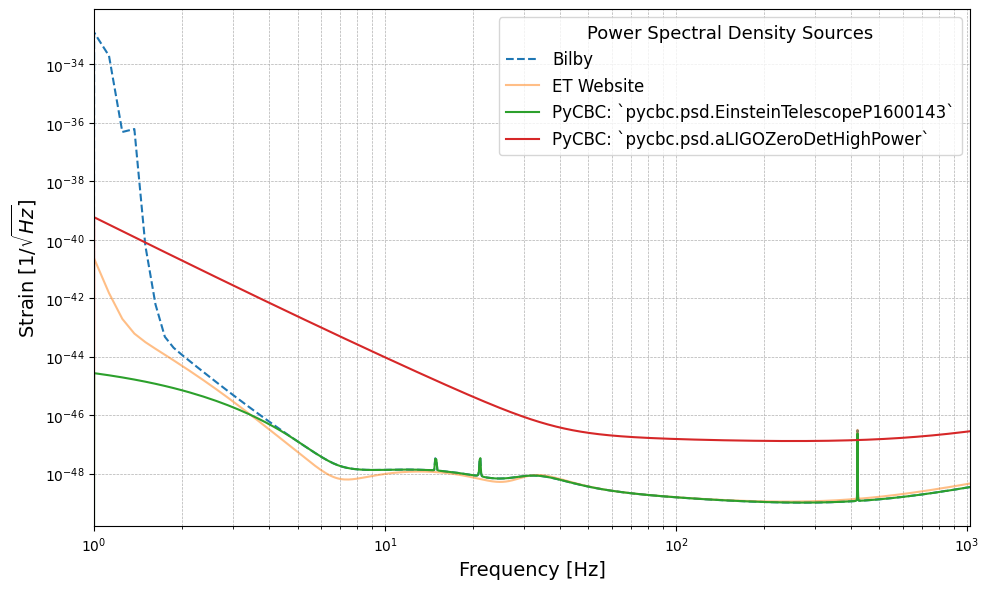

In [25]:
plt.figure(figsize=(10, 6))

plt.plot(psd0.sample_frequencies, psd0, linestyle='--', label="Bilby")
plt.plot(psd1.sample_frequencies, psd1, alpha=0.5, label="ET Website")
plt.plot(
    psd2.sample_frequencies, psd2,
    label="PyCBC: `pycbc.psd.EinsteinTelescopeP1600143`",
)
plt.plot(
    psd3.sample_frequencies, psd3,
    label="PyCBC: `pycbc.psd.aLIGOZeroDetHighPower`",
)

plt.xscale('log')
plt.yscale('log')
plt.xlim(1, 1024)

plt.xlabel("Frequency [Hz]", fontsize=14)
plt.ylabel(r"Strain [$1/\sqrt{Hz}$]", fontsize=14)
plt.legend(title="Power Spectral Density Sources", fontsize=12, title_fontsize=13, loc="best")

plt.grid(True, which="both", ls="--", lw=0.5)
plt.tight_layout()
plt.show()

In [17]:
print(ET1.longitude_radians, ET1.latitude_radians)
print(ET2.longitude_radians, ET2.latitude_radians)
print(ET3.longitude_radians, ET3.latitude_radians)

0.18333805212847526 0.7615118398425818
0.1843576945713848 0.7603208319532082
0.18281643081766386 0.7600332996230341


In [18]:
print(E0.longitude, E0.latitude)
print(E1.longitude, E1.latitude)
print(E2.longitude, E2.latitude)
print(E3.longitude, E3.latitude)

0.1819299673 0.7627046325699999
0.18333805213 0.7615118398400004
0.1840585887 0.7629930799000002
0.1819299673 0.7627046325699999


<span style="color:skyblue; font-size:18px;"><strong>Only ET3's response tensor is different when comparing `PyCBC` and `Bilby`.</strong></span>

In [19]:
print(ET1.detector_tensor, '\n\n', E1.response)
print()
print()
print(ET2.detector_tensor, '\n\n', E2.response)
print()
print()
print(ET3.detector_tensor, '\n\n', E3.response)
print()
print()

[[ 0.16658985 -0.21884947 -0.12996387]
 [-0.21884947 -0.24838204  0.27321496]
 [-0.12996387  0.27321496  0.08179218]] 

 [[ 0.16658988 -0.21884946 -0.1299639 ]
 [-0.21884946 -0.24838209  0.27321496]
 [-0.1299639   0.27321496  0.08179221]]


[[ 0.03183408  0.28895485 -0.08860032]
 [ 0.28895485 -0.17450064 -0.26504012]
 [-0.08860032 -0.26504012  0.14266656]] 

 [[-0.19922116 -0.07022383  0.21890042]
 [-0.07022383  0.42335665 -0.00853466]
 [ 0.21890042 -0.00853466 -0.22413549]]


[[-0.19865781 -0.06985281  0.21887772]
 [-0.06985281  0.42342515 -0.00872144]
 [ 0.21887772 -0.00872144 -0.22476733]] 

 [[ 0.03263134  0.28907327 -0.08893657]
 [ 0.28907327 -0.17497468 -0.26468026]
 [-0.08893657 -0.26468026  0.14234333]]




<span style="color:skyblue; font-size:18px;"><strong>`E0` is apparantely a null detector.</strong></span>

In [20]:
print(E0.response)
print(E2.response)

[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
[[-0.19922116 -0.07022383  0.21890042]
 [-0.07022383  0.42335665 -0.00853466]
 [ 0.21890042 -0.00853466 -0.22413549]]


### In PyCBC, when we print `Detector.response`, we're looking at the response tensor of the detector. This tensor describes how the detector responds to the incoming gravitational wave strain from different directions and polarizations.

The response tensor is a symmetric 3×3 matrix, denoted by:

$$D^{ij}$$

This tensor defines how the detector measures spacetime strain $h_{ij}$. The measured strain $h(t)$ the detector is:

$$
    h(t) = D^{ij} h_{ij}
$$

So, the response tensor captures how a detector, based on its arm orientation and location, projects the full spacetime strain $h_{ij}$  onto a 1D strain signal.

#### E0 is not a valid detector, as it has no **sensitivity**.

---

In [21]:
CE = pycbc.detector.ground.Detector(detector_name='C1')
print(CE.name)
ET = pycbc.detector.ground.Detector(detector_name='E1')
print(ET.name)
LIGO = pycbc.detector.ground.Detector(detector_name='L1')
print(LIGO.name)

C1
E1
L1


In [22]:
CE